In [1]:
import pandas as pd
import numpy as np
import os
import glob
from tqdm import tqdm
import json
from joblib import Parallel, delayed

import matplotlib.pylab as plt
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.cm as cm
import matplotlib.colors as mcolors

import seaborn as sns

import nibabel as nib

import nilearn.plotting as plotting

from scipy.stats import pearsonr, ttest_ind, mannwhitneyu, zscore, sem, f_oneway

from utils import rewrite_subjectID, process_data, correct_OS, load_maps

%load_ext autoreload
%autoreload 2

In [2]:
voxel_res = 2
root =  "/home/joan/Desktop/PROJECTS/Glioblastomas" # "D:\JoanFR_Sano"
os.makedirs(root, exist_ok=True)
MNI_DIR = "/home/joan/Documents/MNI_ICBM_2009b_NLIN_ASYM" # "C:/Users/user/Documents/Data/MNI"
atlas_lobes = f"/home/joan/Documents/Parcellation/USCLobesMNI-ICBM-2009b-NLIN-ASYM/BCI-DNI_brain.labelxMNI-ICBM-2009b-NLIN-ASYM__Warped.nii.gz"
lobe_labels = f"/home/joan/Documents/Parcellation/USCLobesMNI-ICBM-2009b-NLIN-ASYM/BCI-DNI_brain.labels.txt"
atlas_wm = f"/home/joan/Documents/Parcellation/XTRACT_MNI-ICBM-2009b-NLIN-ASYM/xtract-tract-atlases-maxprob5-1mmxMNI-ICBM-2009b-NLIN-ASYM__Warped.nii.gz"
WM_labels = f"/home/joan/Documents/Parcellation/XTRACT_MNI-ICBM-2009b-NLIN-ASYM/XTRACT.labels.txt"
T1_file = os.path.join(MNI_DIR, f"T1_{voxel_res}mm.nii")
T1 = nib.load(T1_file)
T1_brain = nib.load(os.path.join(MNI_DIR, f"T1_{voxel_res}mm_brain_mask.nii"))

Ni, Nj, Nk = T1.get_fdata().shape
ucsf_dir = "Glioblastoma_UCSF-PDGM_v3-20230111"
upenn_dir = "Glioblastoma_UPENN-GBM_v2-20221024"
tissue = "whole"
tdmap = "TDMap-lesion"

## Other
fmt = "svg"
dpi = 300
stream_th = 0
daysXmonth = 365/12
voxel_size = (0.5**3) * (1/1000) # 0.5 (mm³/voxel) X 0.001 (cm³/mm³)   
sites = [0, 1]
n_jobs = 16
nthreads = 2

In [3]:
## Load and process clinical data
DATA = correct_OS(
    process_data(
        root,
        stream_th,
        voxel_size,
        UCSF_dir=ucsf_dir,
        UPENN_dir=upenn_dir,
        z_transform=0,
        cohort_ids=sites
    ),
    cohort_ids=sites,
    n_perms=10
)

# Process and load UCSF maps
ucsf_ids = [rewrite_subjectID(id) for id in DATA.loc[DATA["site"]==0]["ID"].values]
results = Parallel(n_jobs=n_jobs)(
    delayed(load_maps)(
        list_of_subjects=[subj_id],
        nFeatures=Ni * Nj * Nk,
        template=T1_file,
        root=root,
        data_dir=f"{ucsf_dir}/TDMaps_Grade-IV",
        tissue=tissue,
        tdmap=tdmap,
        voxel_res=voxel_res,
        nthreads=nthreads
    ) for subj_id in tqdm(ucsf_ids, desc="Loading UCSF maps")
)
maps_ucsf = np.vstack(results) # Nsubjects x nFeatures
maps_ucsf = np.where(maps_ucsf>=0, maps_ucsf, 0) # The resampling has introduced some small amount of negative numbers ## Be careful and double check

UCSF cohort description --> N = 367
Precentage of censoring: 39.24%

UPENN cohort description --> N = 496
Precentage of censoring: 2.82%

Log-rank test: chi-squared statistic of 12.477916843409249 (p=0.00041179115365043976)
INFO: The effect of site was found to be significant, applying a correction procedure


Performing permutation test for the C-index: 100%|██████████| 10/10 [00:00<00:00, 26.81it/s]


	C-index of  0.5342924496048814 (p=0.0)
	Log HR of the site effect = 0.28700472900893287
Log-rank test after correction: chi-squared statistic of 0.07015271368547941 (p=0.7911145589222199)



Loading UCSF maps: 100%|██████████| 367/367 [00:03<00:00, 99.77it/s] 


In [4]:
# Process and load UPENN maps
upenn_ids = DATA.loc[DATA["site"]==1]["ID"].values
results = Parallel(n_jobs=n_jobs)(
    delayed(load_maps)(
        list_of_subjects=[subj_id],
        nFeatures=Ni * Nj * Nk,
        template=T1_file,
        root=root,
        data_dir=f"{upenn_dir}/TDMaps_IDH1-WT",
        tissue=tissue,
        tdmap=tdmap,
        voxel_res=voxel_res,
        nthreads=nthreads
    ) for subj_id in tqdm(upenn_ids, desc="Loading UPENN maps")
)
maps_upenn = np.vstack(results) # Nsubjects x nFeatures
maps_upenn = np.where(maps_upenn>=0, maps_upenn, 0) # The resampling has introduced some small amount of negative numbers ## Be careful and double check

maps_all = np.vstack((maps_ucsf, maps_upenn))

Loading UPENN maps:   0%|          | 0/496 [00:00<?, ?it/s]

Loading UPENN maps: 100%|██████████| 496/496 [00:03<00:00, 137.92it/s]


In [10]:
from TractDensityComponents import TD_PCA
from components import Projections

normalization = None#'min_max'
save_dir = "results/"

TD_pca = TD_PCA(maps_all, T1, binary_mask=T1_brain, n_components=10)
cmps_ucsf = TD_pca.fit_pca_maps(norm=normalization)
thresholds = TD_pca.explained_variance_plot(save_dir=save_dir, filename=f'{normalization}_normalized_masked.pdf')

#cmps_upenn = TD_pca.transform_maps(maps_upenn)
Project = Projections(TD_pca)
Project.components_to_brain(save_dir=save_dir, filename=f"{normalization}_normalized_masked_loadings.nii.gz")
explained_all, corrs_all, cos_all = Project.LowRank_convergence(maps_all, maps_all, max_components=10, n_jobs=1)

INFO:	TD maps were masked.
INFO:	Training PCA without normalization . . .
INFO:	Principal Components (PCs) found successfully!
INFO:	Unmasking PCA loadings.
INFO:	Saved 4D NIfTI PCA components at results/None_normalized_masked_loadings.nii.gz
INFO:	Performing a low-rank reconstruction with 1 components
INFO:	Unmasking the low-rank reconstruction.
INFO:	Done for 1 components.
INFO:	Performing a low-rank reconstruction with 2 components
INFO:	Unmasking the low-rank reconstruction.
INFO:	Done for 2 components.
INFO:	Performing a low-rank reconstruction with 3 components
INFO:	Unmasking the low-rank reconstruction.
INFO:	Done for 3 components.
INFO:	Performing a low-rank reconstruction with 4 components
INFO:	Unmasking the low-rank reconstruction.
INFO:	Done for 4 components.
INFO:	Performing a low-rank reconstruction with 5 components
INFO:	Unmasking the low-rank reconstruction.
INFO:	Done for 5 components.
INFO:	Performing a low-rank reconstruction with 6 components
INFO:	Unmasking the l

In [11]:
import pandas as pd

In [12]:
df = DATA.copy()
df = df.drop(columns="OS")

In [14]:
new_cols_df = pd.DataFrame(cmps_ucsf, columns=[f"Comp. {i}" for i in range(10)], index=DATA.index)
new_cols_df.head()

,Comp. 0,Comp. 1,Comp. 2,Comp. 3,Comp. 4,Comp. 5,Comp. 6,Comp. 7,Comp. 8,Comp. 9
0,-10755.441217,20961.432781,8498.687434,9653.440947,-9371.799923,3056.594091,943.303245,-847.796141,-1417.398122,2200.442884
1,-13253.861066,-7081.544460,-4635.513220,-751.802766,908.294817,-2626.803460,-3974.904483,-4101.262333,-6474.069070,1046.258341
2,23968.402031,-13436.818240,6776.393122,256.811631,-650.493689,1742.026145,42.319472,-194.433251,2267.097653,1957.656043
3,25874.169483,7060.537397,11898.341728,-7466.889988,2668.507249,158.985634,-8561.981486,845.752342,3448.699765,-1048.269480
4,-14636.139790,23297.735054,14822.212412,-6953.293245,-4730.941406,4206.058740,-848.468406,748.958055,3520.438922,29.827674


In [ ]:
# data = pd.read_csv("CSVs/demographics-TDMaps_streamTH-0.csv")
# data.shape

(396, 27)

In [26]:
column_names = [f'PCA_comp_{i}' for i in range(cmps_ucsf.shape[1])]

df_nmf_weights = pd.DataFrame(cmps_ucsf, columns=column_names)

df = pd.concat([DATA.reset_index(drop=True), df_nmf_weights], axis=1)
# df = DATA

df.head()

,ID,sex,age,site,volume,ltdi,tdi,OS,status,OS (corrected),PCA_comp_0,PCA_comp_1,PCA_comp_2,PCA_comp_3,PCA_comp_4,PCA_comp_5,PCA_comp_6,PCA_comp_7,PCA_comp_8,PCA_comp_9
0,UCSF-PDGM-009,F,68.0,0,157.513875,4.584943,125.455774,389.0,1,389.0,-10755.441217,20961.432781,8498.687434,9653.440947,-9371.799923,3056.594091,943.303245,-847.796141,-1417.398122,2200.442884
1,UCSF-PDGM-004,M,66.0,0,58.872375,2.269988,90.082312,1303.0,1,1303.0,-13253.861066,-7081.544460,-4635.513220,-751.802766,908.294817,-2626.803460,-3974.904483,-4101.262333,-6474.069070,1046.258341
2,UCSF-PDGM-008,M,70.0,0,235.057500,5.576720,106.265873,185.0,1,185.0,23968.402031,-13436.818240,6776.393122,256.811631,-650.493689,1742.026145,42.319472,-194.433251,2267.097653,1957.656043
3,UCSF-PDGM-011,F,68.0,0,172.138125,6.746218,132.010322,133.0,0,133.0,25874.169483,7060.537397,11898.341728,-7466.889988,2668.507249,158.985634,-8561.981486,845.752342,3448.699765,-1048.269480
4,UCSF-PDGM-014,F,64.0,0,271.585125,6.527491,95.183594,313.0,1,313.0,-14636.139790,23297.735054,14822.212412,-6953.293245,-4730.941406,4206.058740,-848.468406,748.958055,3520.438922,29.827674


In [27]:
feature_names = df.columns
df = df.drop(columns=["OS"])

categorical_features = df.select_dtypes(include="object").columns
numerical_features = df.select_dtypes(exclude="object").columns

numerical_features = numerical_features.drop(["OS (corrected)", "status"])
print(numerical_features)

Index(['age', 'site', 'volume', 'ltdi', 'tdi', 'PCA_comp_0', 'PCA_comp_1',
       'PCA_comp_2', 'PCA_comp_3', 'PCA_comp_4', 'PCA_comp_5', 'PCA_comp_6',
       'PCA_comp_7', 'PCA_comp_8', 'PCA_comp_9'],
      dtype='object')


In [28]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder,
    MinMaxScaler,
)
from feature_engine.encoding import (
    RareLabelEncoder,
)
import sklearn

sklearn.set_config(transform_output="pandas")

one_hot_encoder = OneHotEncoder(
    drop="first",
    sparse_output=False,
    handle_unknown="ignore",
)
rle = RareLabelEncoder(n_categories=1, tol=0.01, missing_values='ignore')

categorical_pipeline = Pipeline(
    [
        ("rare_label_encoder", rle),
        ("one_hot_encoder", one_hot_encoder),
    ],
)

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", MinMaxScaler())
])

column_transformer = ColumnTransformer(
    [
        (
            "cat_pipeline",
            categorical_pipeline,
            categorical_features,
        )
    ],
    verbose_feature_names_out=False,
)

full_preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
],
    remainder='passthrough',
    verbose_feature_names_out=False,)

X = full_preprocessor.fit_transform(df)

In [29]:
from lifelines import CoxPHFitter

# Using Cox Proportional Hazards model
cph = CoxPHFitter()
cph.fit(X, 'OS (corrected)', event_col='status')
print(f"Concordance Index: {cph.concordance_index_:.4f}")
# # cph.print_summary()
# cph.plot_covariate_groups('Whole lesion TDMap', values=[0, 1])

Concordance Index: 0.6547


<Axes: xlabel='log(HR) (95% CI)'>

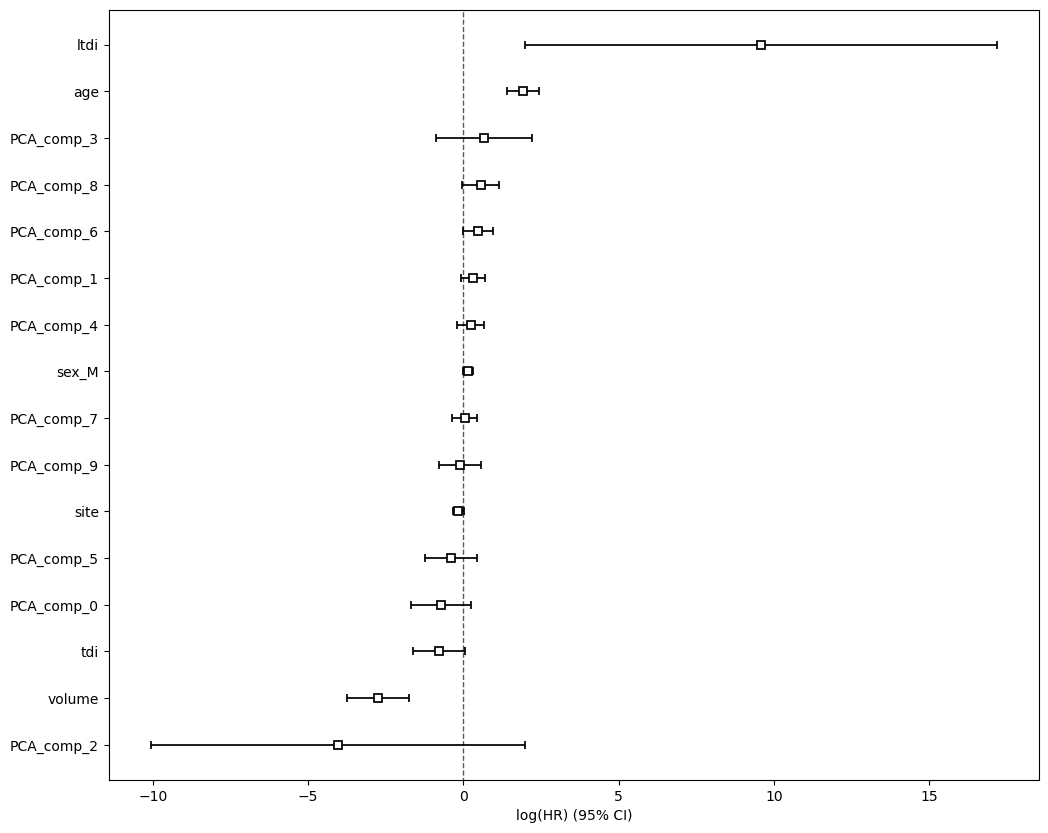

In [30]:
fig, ax = plt.subplots(figsize=(12, 10))

cph.plot(ax = ax)

/tmp/ipykernel_2340396/1378501143.py:11: UserWarning: Non-finite values detected. These values will be replaced with zeros.
  plotting.plot_stat_map(


--- Component 0 ---
Max value: 0.0210
Min value: -0.0160
--------------------
--- Component 1 ---
Max value: 0.0233
Min value: -0.0183
--------------------
--- Component 2 ---
Max value: 0.0253
Min value: -0.0004
--------------------
--- Component 3 ---
Max value: 0.0234
Min value: -0.0204
--------------------
--- Component 4 ---
Max value: 0.0277
Min value: -0.0176
--------------------


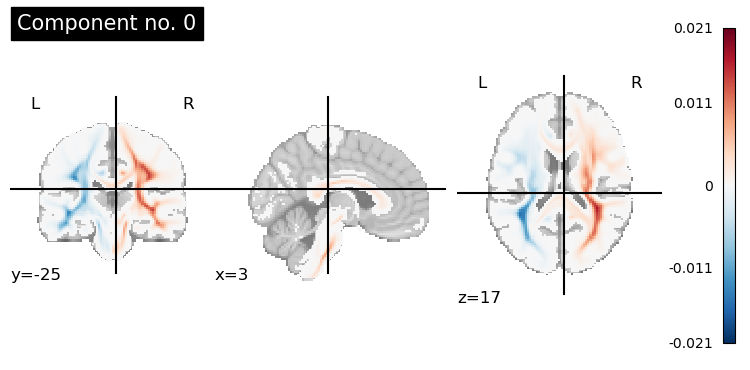

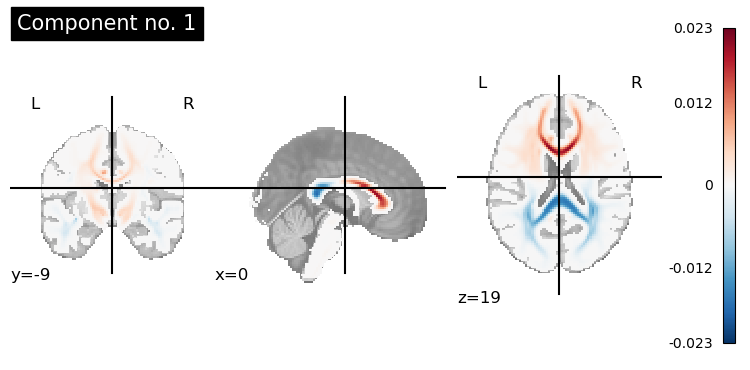

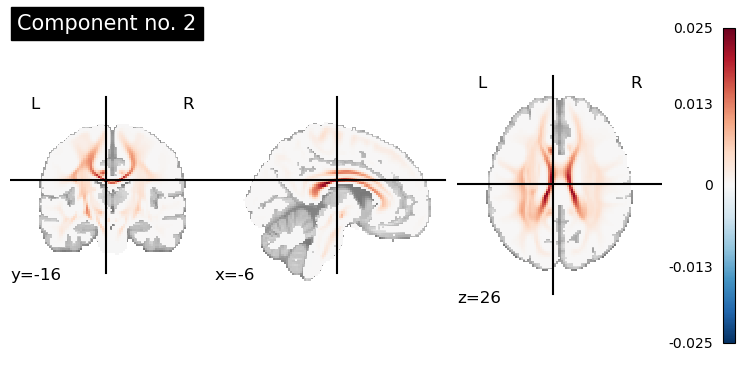

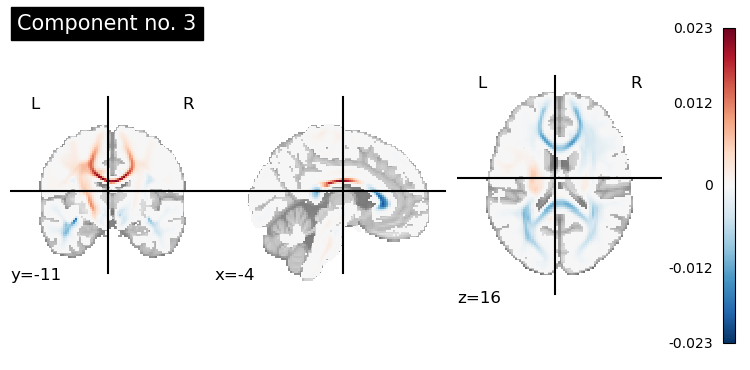

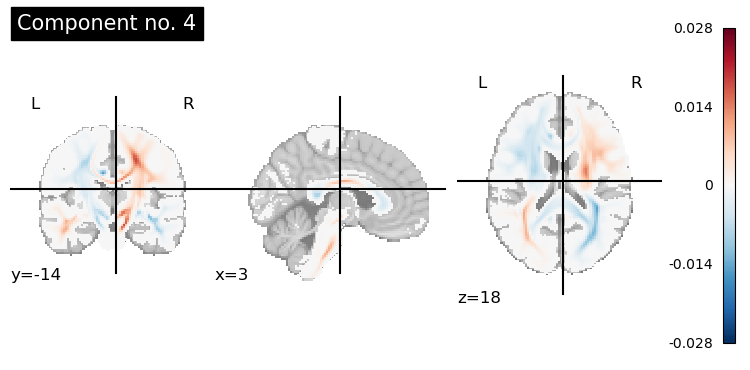

In [36]:
from nilearn import image, plotting


img_path = f"results/{normalization}_normalized_masked_loadings.nii.gz"

num_components = 5 

for no in range(num_components):
    comp_img = image.index_img(img_path, no)
    
    plotting.plot_stat_map(
        comp_img, 
        title=f"Component no. {no}", 
        threshold=1e-6,
        display_mode='ortho',
        colorbar=True
    )
    
    data = comp_img.get_fdata()
    
    print(f"--- Component {no} ---")
    print(f"Max value: {data.max():.4f}")
    print(f"Min value: {data.min():.4f}")
    print("-" * 20)


plotting.show()

/tmp/ipykernel_2340396/1340635703.py:13: UserWarning: Non-finite values detected. These values will be replaced with zeros.
  plotting.plot_stat_map(


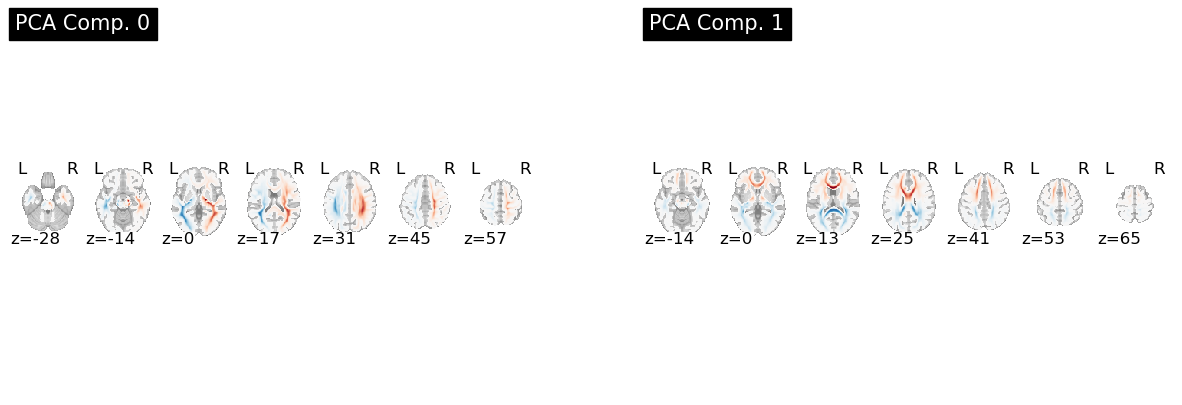

In [41]:
import matplotlib.pyplot as plt
from nilearn import image, plotting

img_path = f"results/{normalization}_normalized_masked_loadings.nii.gz"
n_comp = 2

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))
axes = axes.flatten()

for no in range(n_comp):
    comp_img = image.index_img(img_path, no)
    
    plotting.plot_stat_map(
        comp_img, 
        title=f"PCA Comp. {no}", 
        axes=axes[no], 
        display_mode='z',
        colorbar=False, 
        threshold=1e-5
    )

plt.show()

In [42]:
sorted_params = cph.params_.sort_values(ascending=False, key=abs)
print(sorted_params)

covariate
ltdi          9.575348
PCA_comp_2   -4.037936
volume       -2.754046
age           1.914217
tdi          -0.782074
PCA_comp_0   -0.724531
PCA_comp_3    0.662248
PCA_comp_8    0.550144
PCA_comp_6    0.467206
PCA_comp_5   -0.387303
PCA_comp_1    0.308029
PCA_comp_4    0.230960
site         -0.160445
sex_M         0.144430
PCA_comp_9   -0.113259
PCA_comp_7    0.037157
Name: coef, dtype: float64


In [43]:
cph.params_.sort_values(ascending=False)

covariate
ltdi          9.575348
age           1.914217
PCA_comp_3    0.662248
PCA_comp_8    0.550144
PCA_comp_6    0.467206
PCA_comp_1    0.308029
PCA_comp_4    0.230960
sex_M         0.144430
PCA_comp_7    0.037157
PCA_comp_9   -0.113259
site         -0.160445
PCA_comp_5   -0.387303
PCA_comp_0   -0.724531
tdi          -0.782074
volume       -2.754046
PCA_comp_2   -4.037936
Name: coef, dtype: float64